# Phase 6 — Feature Importance & Interpretation

**Objective:** Explain *why* the best-performing model (Random Forest) makes its predictions and identify which soil/environmental factors most influence crop selection.

**Best Model:** Random Forest (Test Accuracy: 99.55%, F1-macro: 0.9955) — selected in Phase 5

**Analyses:**
1. **Built-in feature importance** (Mean Decrease Impurity / Gini importance)
2. **Permutation importance** (model-agnostic, measures accuracy drop)
3. **SHAP values** (Shapley Additive Explanations — granular, per-sample attribution)
4. **Per-crop feature profiles** (which features matter for which crop)
5. **Agronomic interpretation** (connecting ML results to domain knowledge)

**Inputs:** `models/random_forest.joblib`, `X_train.csv`, `X_test.csv`, `y_test.csv`, `preprocessing_pipeline.joblib`

## 1. Setup & Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import warnings
import shap

from sklearn.inspection import permutation_importance

warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='husl', font_scale=1.1)
plt.rcParams.update({
    'figure.dpi': 120,
    'figure.facecolor': '#f8f9fa',
    'axes.facecolor': '#ffffff',
    'axes.edgecolor': '#dee2e6',
    'grid.color': '#e9ecef',
    'font.family': 'sans-serif',
})

RANDOM_STATE = 42

print('\u2705 All libraries imported successfully.')
print(f'   SHAP version: {shap.__version__}')

✅ All libraries imported successfully.
   SHAP version: 0.52.0


C:\Users\Aryan Mishra\OneDrive\Desktop\Crop\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load Best Model & Data

In [2]:
# Load the best model (Random Forest from Phase 5)
rf_model = joblib.load('models/random_forest.joblib')
print(f'\u2705 Loaded Random Forest model: {rf_model.n_estimators} trees')

# Load data
X_train = pd.read_csv('X_train.csv')
X_test  = pd.read_csv('X_test.csv')
y_train = pd.read_csv('y_train.csv')['label_encoded'].values
y_test  = pd.read_csv('y_test.csv')['label_encoded'].values

# Load label encoder
pipeline = joblib.load('preprocessing_pipeline.joblib')
label_encoder = pipeline['label_encoder']
class_names = label_encoder.classes_
feature_cols = list(X_train.columns)

print(f'\u2705 Loaded data splits: X_train {X_train.shape}, X_test {X_test.shape}')
print(f'   Features: {feature_cols}')
print(f'   Classes:  {len(class_names)} crops')

✅ Loaded Random Forest model: 200 trees
✅ Loaded data splits: X_train (1760, 7), X_test (440, 7)
   Features: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
   Classes:  22 crops


## 3. Built-in Feature Importance (Mean Decrease Impurity)

Random Forest provides `feature_importances_` out of the box. This measures **Mean Decrease Impurity (MDI)** — the total reduction in Gini impurity that each feature contributes across all 200 trees.

| Metric | Meaning |
|---|---|
| **MDI (Gini importance)** | How much each feature reduces classification uncertainty on average |
| **Higher = more important** | The feature is used more often at critical split points in the trees |

> **Caveat:** MDI can be biased toward high-cardinality or continuous features. We validate with permutation importance and SHAP below.

=== Mean Decrease Impurity (Gini) Feature Importance ===
    Feature  Importance   Pct  Cumulative Pct
   rainfall    0.219641 21.96           21.96
   humidity    0.217058 21.71           43.67
          K    0.180813 18.08           61.75
          P    0.151342 15.13           76.88
          N    0.103356 10.34           87.22
temperature    0.075485  7.55           94.77
         ph    0.052305  5.23          100.00


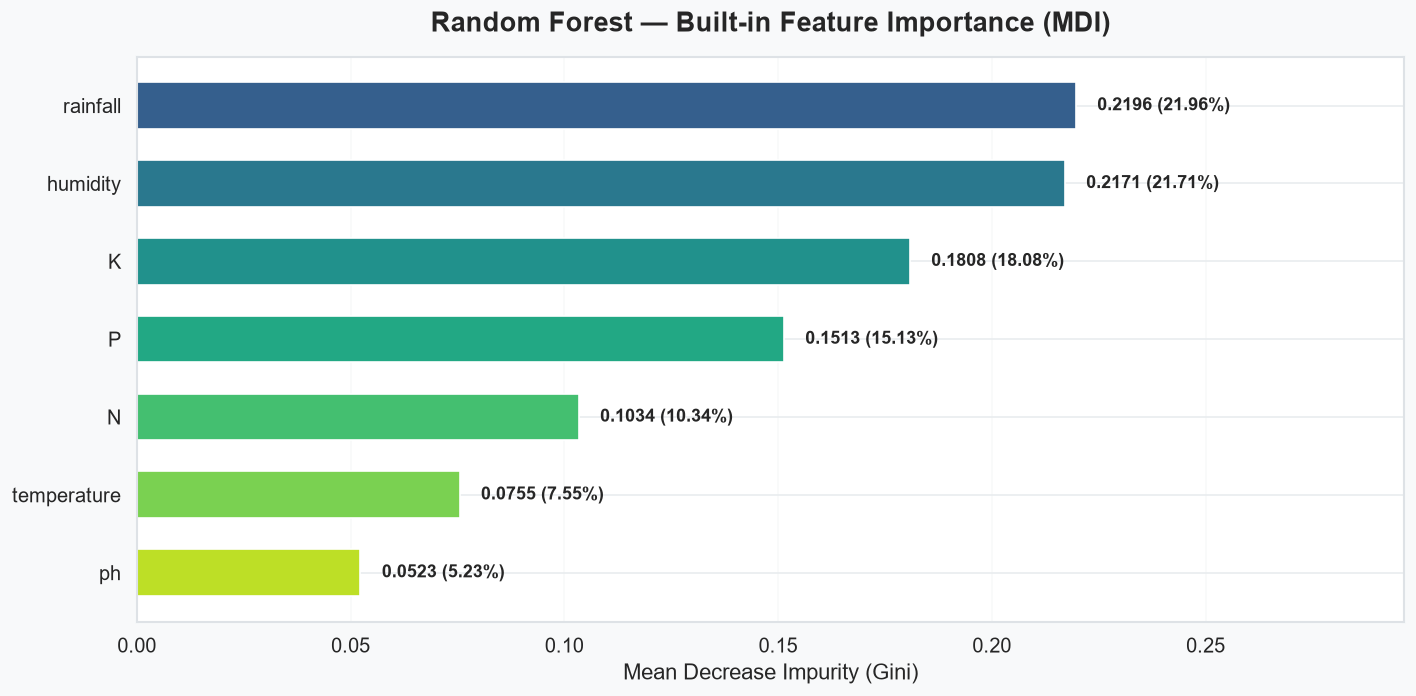

In [3]:
# ============================================================
# Built-in feature importance (Gini / MDI)
# ============================================================
importances_mdi = rf_model.feature_importances_
mdi_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': importances_mdi
}).sort_values('Importance', ascending=False).reset_index(drop=True)
mdi_df['Pct'] = (mdi_df['Importance'] / mdi_df['Importance'].sum() * 100).round(2)
mdi_df['Cumulative Pct'] = mdi_df['Pct'].cumsum().round(2)

print('=== Mean Decrease Impurity (Gini) Feature Importance ===')
print(mdi_df.to_string(index=False))

# --- Bar chart ---
fig, ax = plt.subplots(figsize=(12, 6))
colors = plt.cm.viridis(np.linspace(0.3, 0.9, len(mdi_df)))
bars = ax.barh(mdi_df['Feature'][::-1], mdi_df['Importance'][::-1],
               color=colors[::-1], edgecolor='white', height=0.6)

for bar, pct in zip(bars, mdi_df['Pct'][::-1]):
    ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2,
            f'{bar.get_width():.4f} ({pct}%)', va='center', fontsize=11, fontweight='bold')

ax.set_xlabel('Mean Decrease Impurity (Gini)', fontsize=13)
ax.set_title('Random Forest — Built-in Feature Importance (MDI)',
             fontsize=16, fontweight='bold', pad=15)
ax.grid(axis='x', alpha=0.3)
ax.set_xlim(0, max(importances_mdi) * 1.35)
plt.tight_layout()
plt.show()

## 4. Permutation Importance

**Permutation importance** is model-agnostic and avoids MDI's bias. It measures how much the model's accuracy **drops** when each feature's values are randomly shuffled — breaking the relationship between feature and target.

| Advantage over MDI | Explanation |
|---|---|
| **No bias toward continuous features** | Measures actual predictive power, not just split frequency |
| **Uses test data** | Reflects generalization importance, not training-set artifacts |
| **Captures feature interactions** | Shuffling one feature disrupts its interactions too |

=== Permutation Importance (30 repeats, test set) ===
    Feature  Mean Importance      Std
   humidity         0.322424 0.017748
          N         0.225455 0.016362
   rainfall         0.177803 0.012595
          K         0.166364 0.011683
          P         0.107348 0.014678
         ph         0.011212 0.004020
temperature         0.006667 0.003418


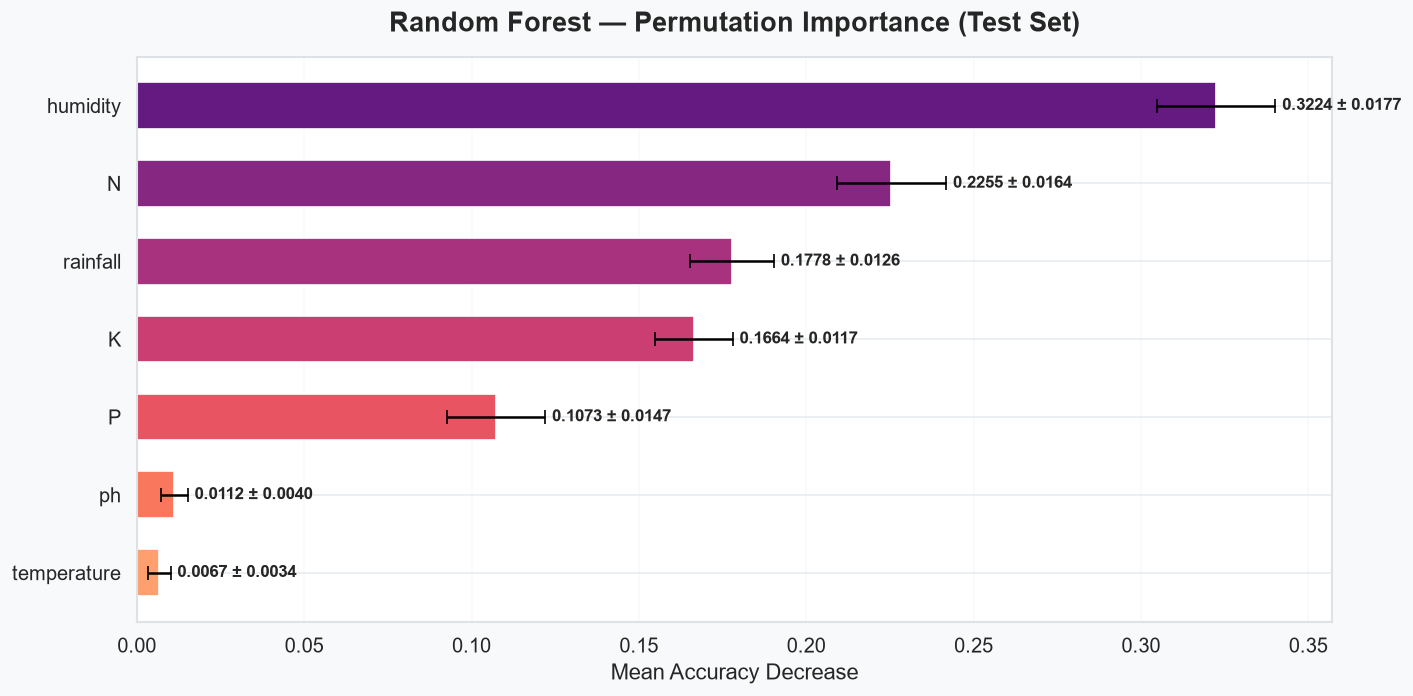

In [4]:
# ============================================================
# Permutation Importance (on test set)
# ============================================================
perm_result = permutation_importance(
    rf_model, X_test, y_test,
    n_repeats=30,
    random_state=RANDOM_STATE,
    scoring='accuracy',
    n_jobs=-1
)

perm_df = pd.DataFrame({
    'Feature': feature_cols,
    'Mean Importance': perm_result.importances_mean,
    'Std': perm_result.importances_std,
}).sort_values('Mean Importance', ascending=False).reset_index(drop=True)

print('=== Permutation Importance (30 repeats, test set) ===')
print(perm_df.to_string(index=False))

# --- Bar chart with error bars ---
fig, ax = plt.subplots(figsize=(12, 6))
colors = plt.cm.magma(np.linspace(0.3, 0.8, len(perm_df)))

ax.barh(perm_df['Feature'][::-1], perm_df['Mean Importance'][::-1],
        xerr=perm_df['Std'][::-1],
        color=colors[::-1], edgecolor='white', height=0.6,
        capsize=4, error_kw={'linewidth': 1.5})

for i, (mean, std) in enumerate(zip(perm_df['Mean Importance'][::-1], perm_df['Std'][::-1])):
    ax.text(mean + std + 0.002, i,
            f'{mean:.4f} \u00b1 {std:.4f}', va='center', fontsize=10, fontweight='bold')

ax.set_xlabel('Mean Accuracy Decrease', fontsize=13)
ax.set_title('Random Forest — Permutation Importance (Test Set)',
             fontsize=16, fontweight='bold', pad=15)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

### MDI vs Permutation Importance — Side-by-Side

Comparing the two methods validates which features are genuinely important vs. artifacts of the MDI calculation.

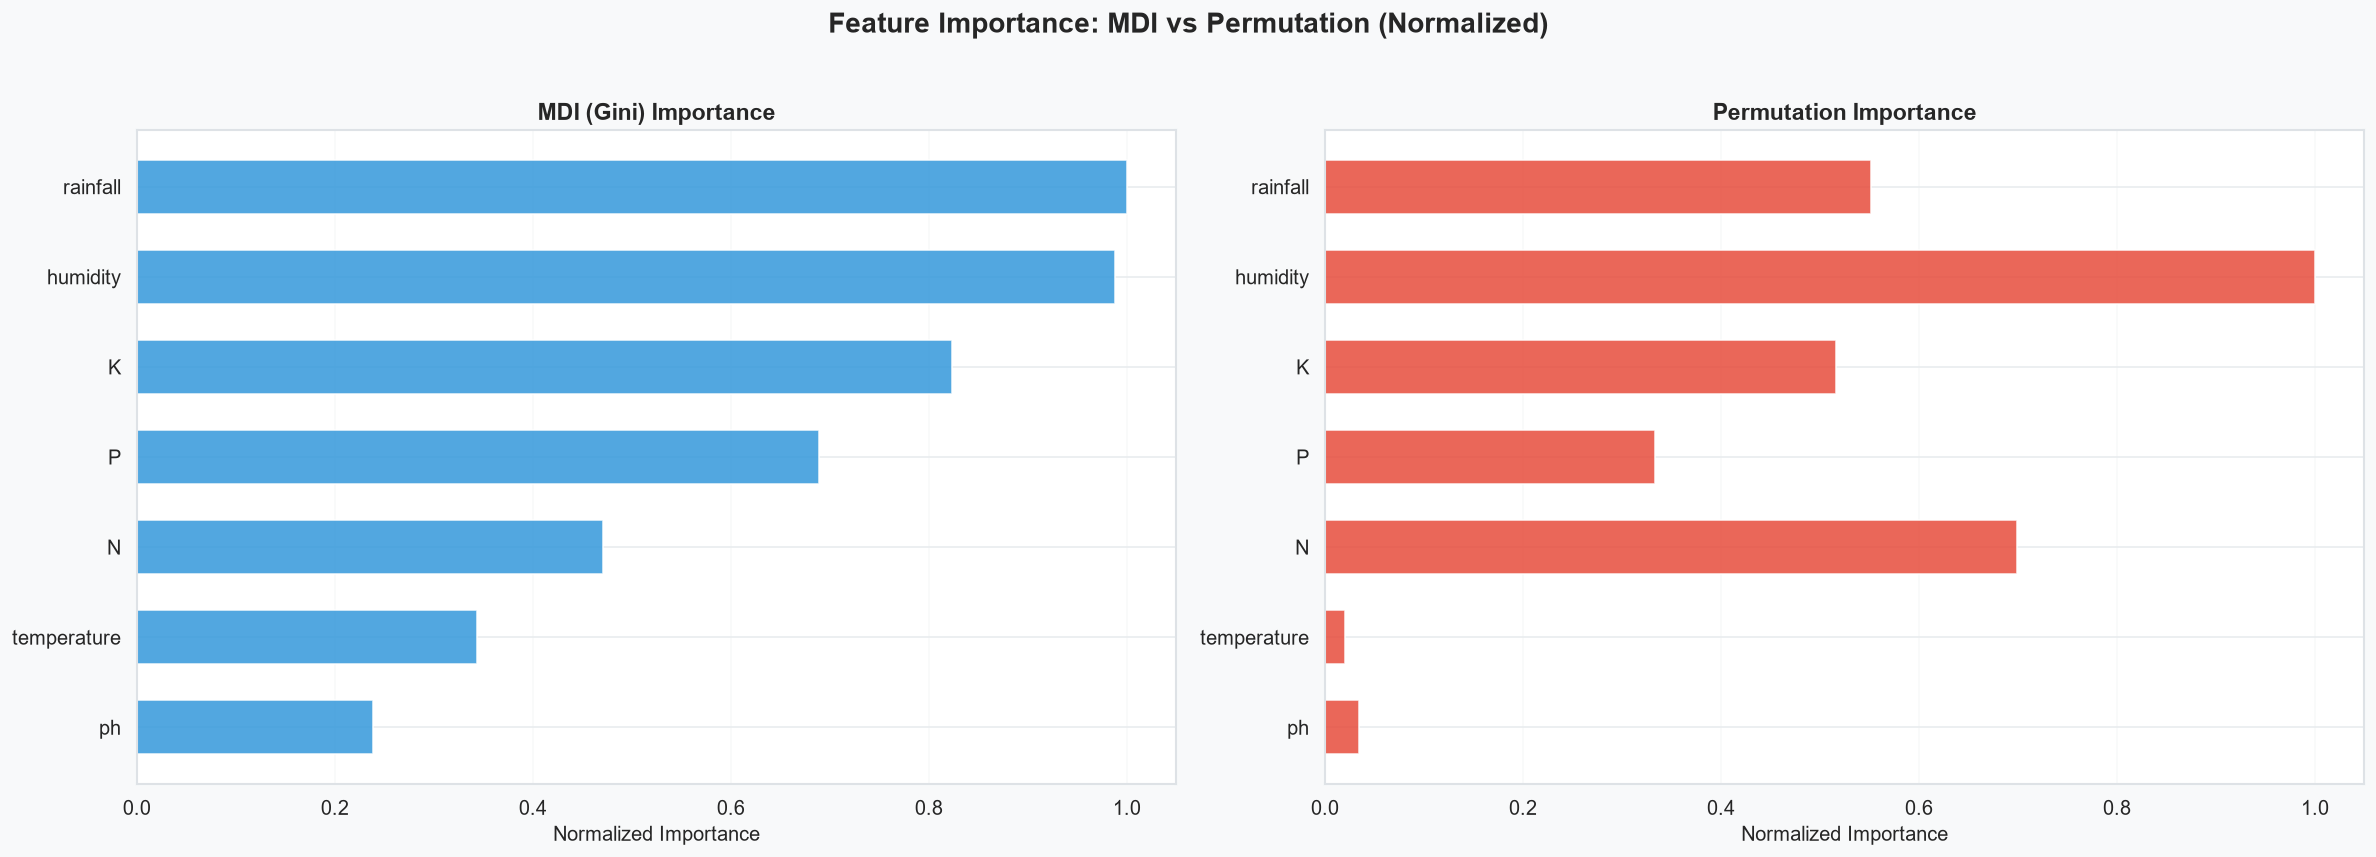

=== Rank Comparison ===
    Feature  MDI Rank  Perm Rank  Rank Diff
   rainfall         1          3          2
   humidity         2          1          1
          K         3          4          1
          P         4          5          1
          N         5          2          3
temperature         6          7          1
         ph         7          6          1

Average rank difference: 1.4
✅ Both methods broadly agree on feature importance ranking.


In [5]:
# ============================================================
# Side-by-side: MDI vs Permutation Importance
# ============================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 7))

# Normalize both to [0, 1] for fair visual comparison
mdi_norm = mdi_df.set_index('Feature')['Importance']
mdi_norm = mdi_norm / mdi_norm.max()

perm_norm = perm_df.set_index('Feature')['Mean Importance']
perm_norm = perm_norm / perm_norm.max()

# Common order (by MDI rank)
order = mdi_df['Feature'].tolist()

ax1.barh(order[::-1], [mdi_norm[f] for f in order[::-1]],
         color='#3498db', edgecolor='white', height=0.6, alpha=0.85)
ax1.set_title('MDI (Gini) Importance', fontsize=14, fontweight='bold')
ax1.set_xlabel('Normalized Importance', fontsize=12)
ax1.grid(axis='x', alpha=0.3)

ax2.barh(order[::-1], [perm_norm.get(f, 0) for f in order[::-1]],
         color='#e74c3c', edgecolor='white', height=0.6, alpha=0.85)
ax2.set_title('Permutation Importance', fontsize=14, fontweight='bold')
ax2.set_xlabel('Normalized Importance', fontsize=12)
ax2.grid(axis='x', alpha=0.3)

plt.suptitle('Feature Importance: MDI vs Permutation (Normalized)',
             fontsize=17, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Rank comparison table
rank_compare = pd.DataFrame({
    'Feature': order,
    'MDI Rank': range(1, len(order) + 1),
    'Perm Rank': [perm_df[perm_df['Feature'] == f].index[0] + 1 for f in order],
})
rank_compare['Rank Diff'] = abs(rank_compare['MDI Rank'] - rank_compare['Perm Rank'])
print('=== Rank Comparison ===')
print(rank_compare.to_string(index=False))
print(f'\nAverage rank difference: {rank_compare["Rank Diff"].mean():.1f}')
if rank_compare['Rank Diff'].mean() < 1.5:
    print('\u2705 Both methods broadly agree on feature importance ranking.')
else:
    print('\u26a0\ufe0f  Notable disagreement between methods — see analysis below.')

## 5. SHAP Analysis (SHapley Additive exPlanations)

SHAP provides the most granular view of feature importance:
- **Global importance** — which features matter overall
- **Per-sample explanations** — why a specific prediction was made
- **Feature interaction effects** — how features combine
- **Direction of effect** — does a high value push toward or away from a class

We use `TreeExplainer` which is optimized for tree-based models like Random Forest.

In [6]:
# ============================================================
# SHAP TreeExplainer for Random Forest
# ============================================================
# Use a sample of test data for SHAP (full test set for RF is tractable)
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer(X_test)

print(f'\u2705 SHAP values computed.')
print(f'   Shape: {shap_values.values.shape}')
print(f'   (samples, features, classes) = ({X_test.shape[0]}, {len(feature_cols)}, {len(class_names)})')

✅ SHAP values computed.
   Shape: (440, 7, 22)
   (samples, features, classes) = (440, 7, 22)


### 5a. SHAP Global Feature Importance (Bar Plot)

The mean absolute SHAP value across all samples and classes shows each feature's overall contribution to predictions.

=== SHAP Global Feature Importance ===
    Feature  Mean |SHAP|
   humidity     0.032209
          K     0.027702
   rainfall     0.025944
          N     0.025862
          P     0.024163
temperature     0.010504
         ph     0.004884


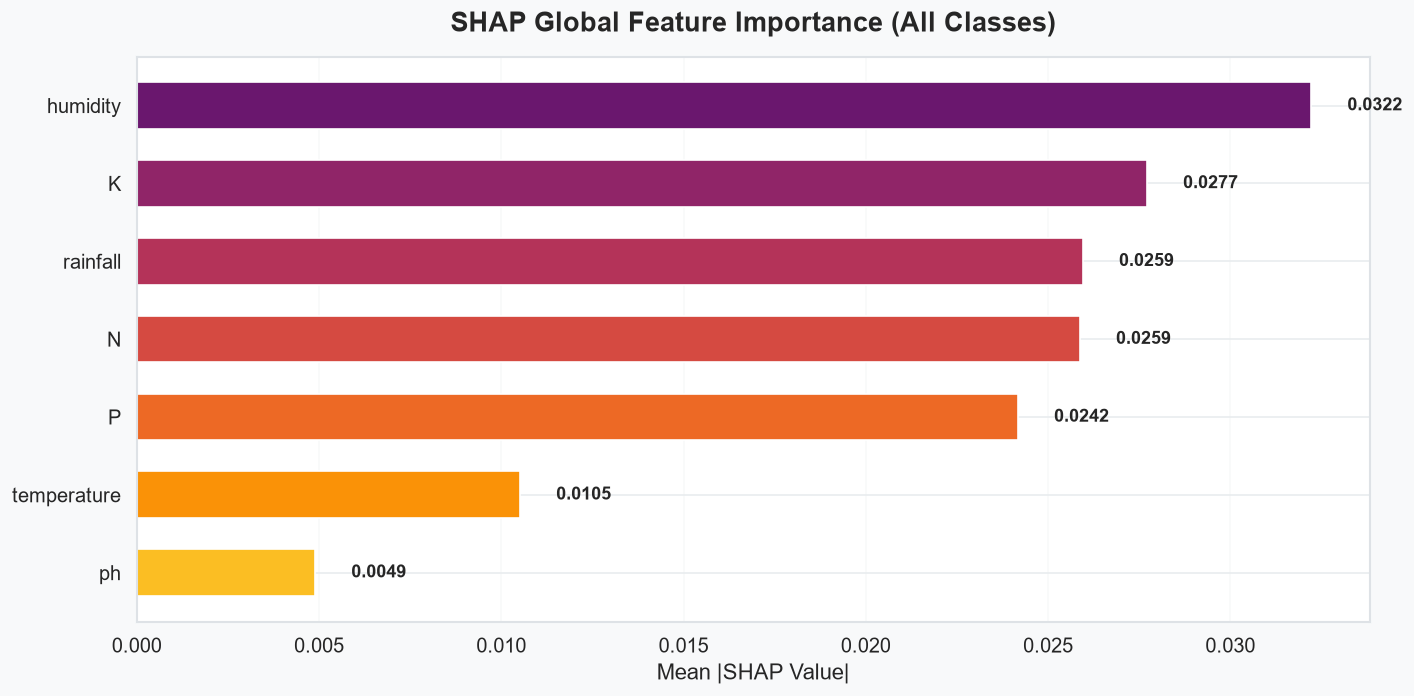

In [7]:
# ============================================================
# SHAP Global Bar Plot — mean |SHAP| across all classes
# ============================================================
# Average absolute SHAP values across all classes for global importance
mean_abs_shap = np.abs(shap_values.values).mean(axis=(0, 2))  # mean over samples and classes

shap_global_df = pd.DataFrame({
    'Feature': feature_cols,
    'Mean |SHAP|': mean_abs_shap
}).sort_values('Mean |SHAP|', ascending=False).reset_index(drop=True)

print('=== SHAP Global Feature Importance ===')
print(shap_global_df.to_string(index=False))

# Custom bar chart
fig, ax = plt.subplots(figsize=(12, 6))
colors = plt.cm.inferno(np.linspace(0.3, 0.85, len(shap_global_df)))
bars = ax.barh(shap_global_df['Feature'][::-1], shap_global_df['Mean |SHAP|'][::-1],
               color=colors[::-1], edgecolor='white', height=0.6)

for bar in bars:
    ax.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2,
            f'{bar.get_width():.4f}', va='center', fontsize=11, fontweight='bold')

ax.set_xlabel('Mean |SHAP Value|', fontsize=13)
ax.set_title('SHAP Global Feature Importance (All Classes)',
             fontsize=16, fontweight='bold', pad=15)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

### 5b. SHAP Beeswarm Plot (Summary)

The beeswarm plot shows every sample's SHAP value for each feature, colored by the feature's actual value. This reveals **direction of effect** — do high values push the prediction toward or away from certain crops.

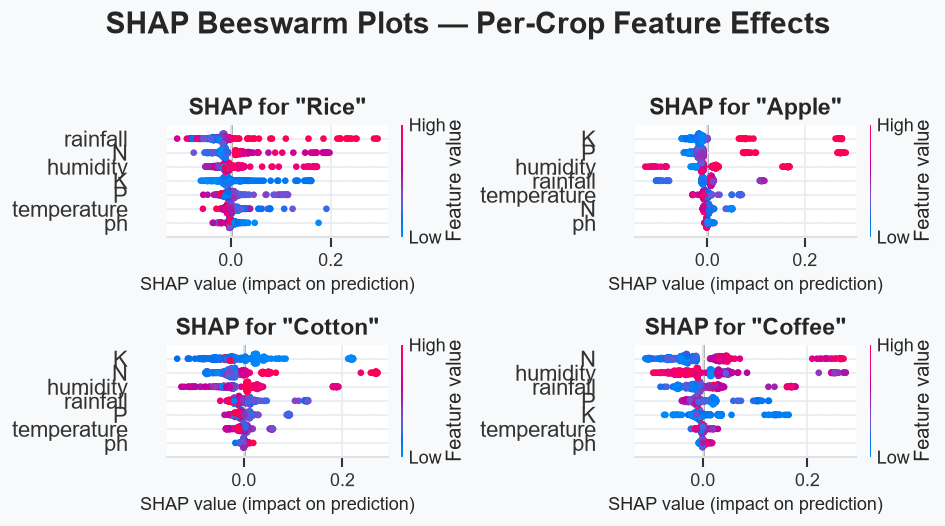


Reading the beeswarm:
  • Each dot = one test sample
  • Color = feature value (red = high, blue = low)
  • X-axis = SHAP value (positive = pushes toward this crop, negative = away)


In [8]:
# ============================================================
# SHAP Beeswarm for top 4 most interesting crops
# ============================================================
# For multi-class, show beeswarm for a few representative crops
# Pick crops with interesting feature profiles: rice (water-intensive),
# apple (temperate), cotton (NPK-heavy), coffee (ph-sensitive)
interesting_crops = ['rice', 'apple', 'cotton', 'coffee']

fig, axes = plt.subplots(2, 2, figsize=(22, 14))

for ax, crop_name in zip(axes.flatten(), interesting_crops):
    class_idx = list(class_names).index(crop_name)
    # Create single-output SHAP explanation for this class
    shap_class = shap.Explanation(
        values=shap_values.values[:, :, class_idx],
        base_values=shap_values.base_values[:, class_idx],
        data=shap_values.data,
        feature_names=feature_cols
    )
    plt.sca(ax)
    shap.plots.beeswarm(shap_class, show=False, max_display=7)
    ax.set_title(f'SHAP for "{crop_name.capitalize()}"', fontsize=14, fontweight='bold')
    ax.set_xlabel('SHAP value (impact on prediction)', fontsize=11)

plt.suptitle('SHAP Beeswarm Plots — Per-Crop Feature Effects',
             fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print('\nReading the beeswarm:')
print('  • Each dot = one test sample')
print('  • Color = feature value (red = high, blue = low)')
print('  • X-axis = SHAP value (positive = pushes toward this crop, negative = away)')

### 5c. SHAP Feature Importance per Crop (Heatmap)

This heatmap shows the mean |SHAP value| for each (feature, crop) pair — revealing **which features drive which crop recommendations**.

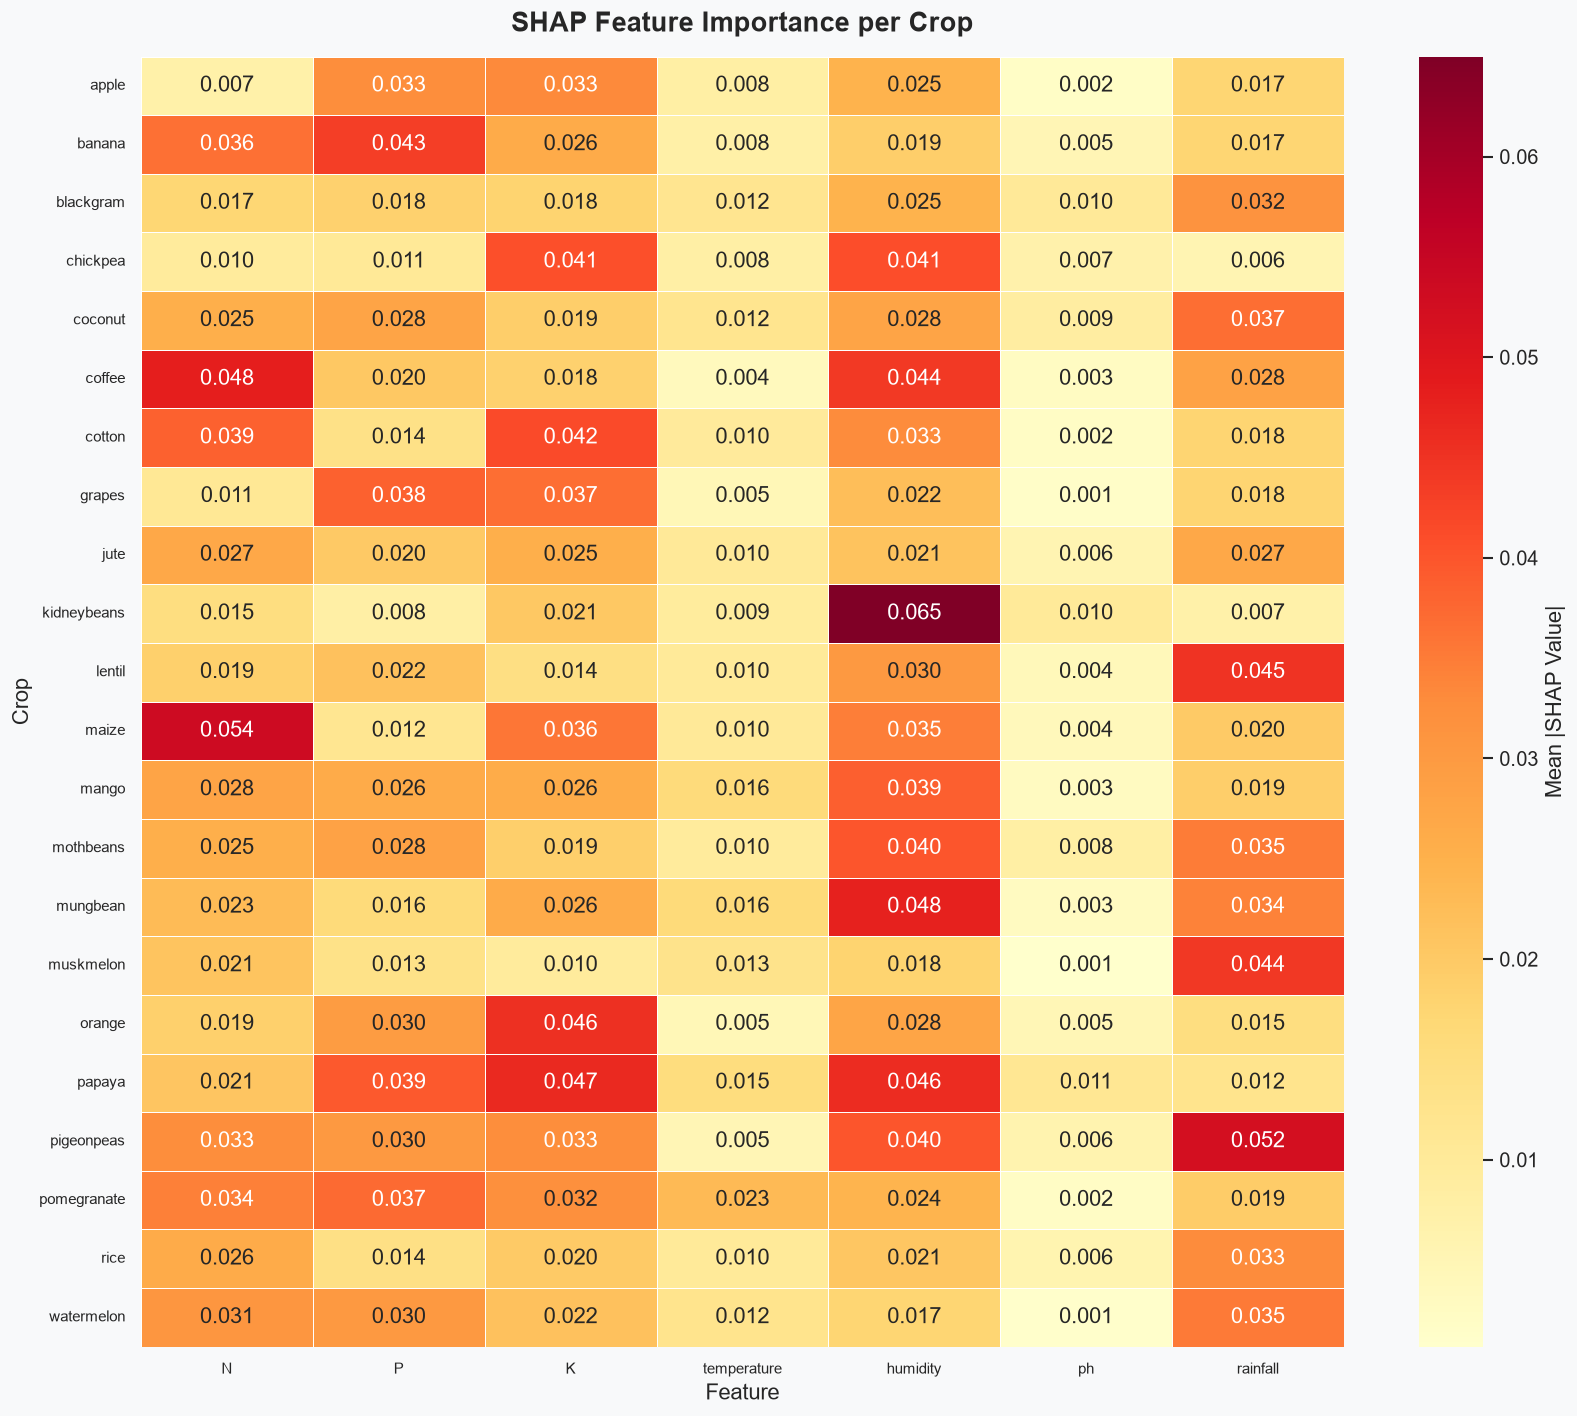


=== Most Important Feature per Crop ===
  apple           → K (mean |SHAP| = 0.0332)
  banana          → P (mean |SHAP| = 0.0433)
  blackgram       → rainfall (mean |SHAP| = 0.0316)
  chickpea        → humidity (mean |SHAP| = 0.0411)
  coconut         → rainfall (mean |SHAP| = 0.0367)
  coffee          → N (mean |SHAP| = 0.0483)
  cotton          → K (mean |SHAP| = 0.0416)
  grapes          → P (mean |SHAP| = 0.0385)
  jute            → rainfall (mean |SHAP| = 0.0269)
  kidneybeans     → humidity (mean |SHAP| = 0.0650)
  lentil          → rainfall (mean |SHAP| = 0.0451)
  maize           → N (mean |SHAP| = 0.0536)
  mango           → humidity (mean |SHAP| = 0.0386)
  mothbeans       → humidity (mean |SHAP| = 0.0401)
  mungbean        → humidity (mean |SHAP| = 0.0479)
  muskmelon       → rainfall (mean |SHAP| = 0.0442)
  orange          → K (mean |SHAP| = 0.0456)
  papaya          → K (mean |SHAP| = 0.0466)
  pigeonpeas      → rainfall (mean |SHAP| = 0.0524)
  pomegranate     → P (mean

In [9]:
# ============================================================
# SHAP per-crop heatmap: mean |SHAP| for each (feature, crop)
# ============================================================
shap_per_crop = np.zeros((len(class_names), len(feature_cols)))

for c_idx, crop in enumerate(class_names):
    # Mean absolute SHAP for this class across all samples
    shap_per_crop[c_idx, :] = np.abs(shap_values.values[:, :, c_idx]).mean(axis=0)

shap_crop_df = pd.DataFrame(
    shap_per_crop, index=class_names, columns=feature_cols
)

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(
    shap_crop_df, annot=True, fmt='.3f', cmap='YlOrRd',
    linewidths=0.5, linecolor='white',
    cbar_kws={'label': 'Mean |SHAP Value|'},
    ax=ax
)
ax.set_title('SHAP Feature Importance per Crop',
             fontsize=16, fontweight='bold', pad=15)
ax.set_xlabel('Feature', fontsize=13)
ax.set_ylabel('Crop', fontsize=13)
ax.tick_params(axis='both', labelsize=9)
plt.tight_layout()
plt.show()

# Print the top feature for each crop
print('\n=== Most Important Feature per Crop ===')
for crop in class_names:
    top_feat = shap_crop_df.loc[crop].idxmax()
    top_val = shap_crop_df.loc[crop].max()
    print(f'  {crop:15s} → {top_feat} (mean |SHAP| = {top_val:.4f})')

## 6. Per-Tree Importance Variability

Random Forest is an ensemble of 200 trees. Each tree has its own feature importance scores. Plotting the distribution across all trees reveals how **consistent** each feature's importance is.

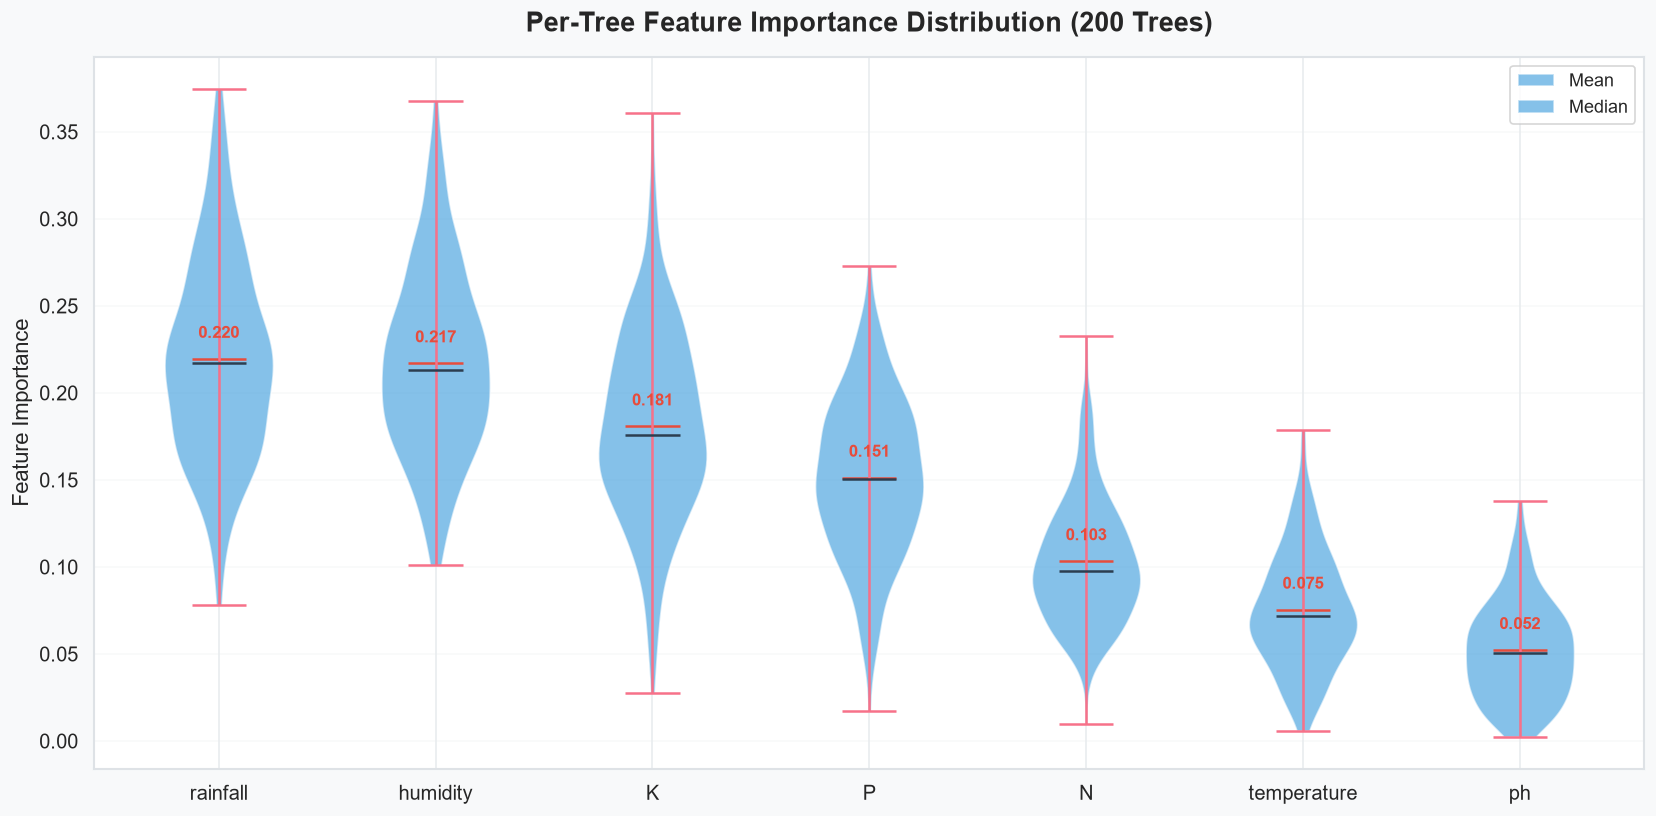


Interpretation:
  • Narrow violins = the feature's importance is consistent across trees
  • Wide violins = importance varies, suggesting context-dependent splits


In [10]:
# ============================================================
# Per-tree feature importance distribution (violin plot)
# ============================================================
tree_importances = np.array([tree.feature_importances_ for tree in rf_model.estimators_])
# shape: (200 trees, 7 features)

# Order by mean importance
order_idx = np.argsort(tree_importances.mean(axis=0))[::-1]
ordered_features = [feature_cols[i] for i in order_idx]
ordered_importances = tree_importances[:, order_idx]

fig, ax = plt.subplots(figsize=(14, 7))
parts = ax.violinplot(
    ordered_importances, positions=range(len(feature_cols)),
    showmeans=True, showmedians=True, showextrema=True
)

# Style the violins
for pc in parts['bodies']:
    pc.set_facecolor('#3498db')
    pc.set_alpha(0.6)
parts['cmeans'].set_color('#e74c3c')
parts['cmedians'].set_color('#2c3e50')

# Add mean values as text
for i, feat in enumerate(ordered_features):
    mean_val = ordered_importances[:, i].mean()
    ax.text(i, mean_val + 0.012, f'{mean_val:.3f}',
            ha='center', fontsize=10, fontweight='bold', color='#e74c3c')

ax.set_xticks(range(len(feature_cols)))
ax.set_xticklabels(ordered_features, fontsize=12)
ax.set_ylabel('Feature Importance', fontsize=13)
ax.set_title('Per-Tree Feature Importance Distribution (200 Trees)',
             fontsize=16, fontweight='bold', pad=15)
ax.grid(axis='y', alpha=0.3)
ax.legend(['Mean', 'Median'], loc='upper right', fontsize=11)

plt.tight_layout()
plt.show()

print('\nInterpretation:')
print('  • Narrow violins = the feature\'s importance is consistent across trees')
print('  • Wide violins = importance varies, suggesting context-dependent splits')

## 7. Unified Importance Comparison (All 3 Methods)

Side-by-side comparison of MDI, Permutation, and SHAP importance to identify features that are consistently ranked as important across all methodologies.

=== Unified Feature Importance (All 3 Methods) ===
                    Feature       MDI  Permutation      SHAP  Avg Rank
Consensus Rank                                                        
1                  humidity  0.217058     0.322424  0.032209  1.333333
2                  rainfall  0.219641     0.177803  0.025944  2.333333
3                         K  0.180813     0.166364  0.027702  3.000000
4                         N  0.103356     0.225455  0.025862  3.666667
5                         P  0.151342     0.107348  0.024163  4.666667
6               temperature  0.075485     0.006667  0.010504  6.333333
7                        ph  0.052305     0.011212  0.004884  6.666667


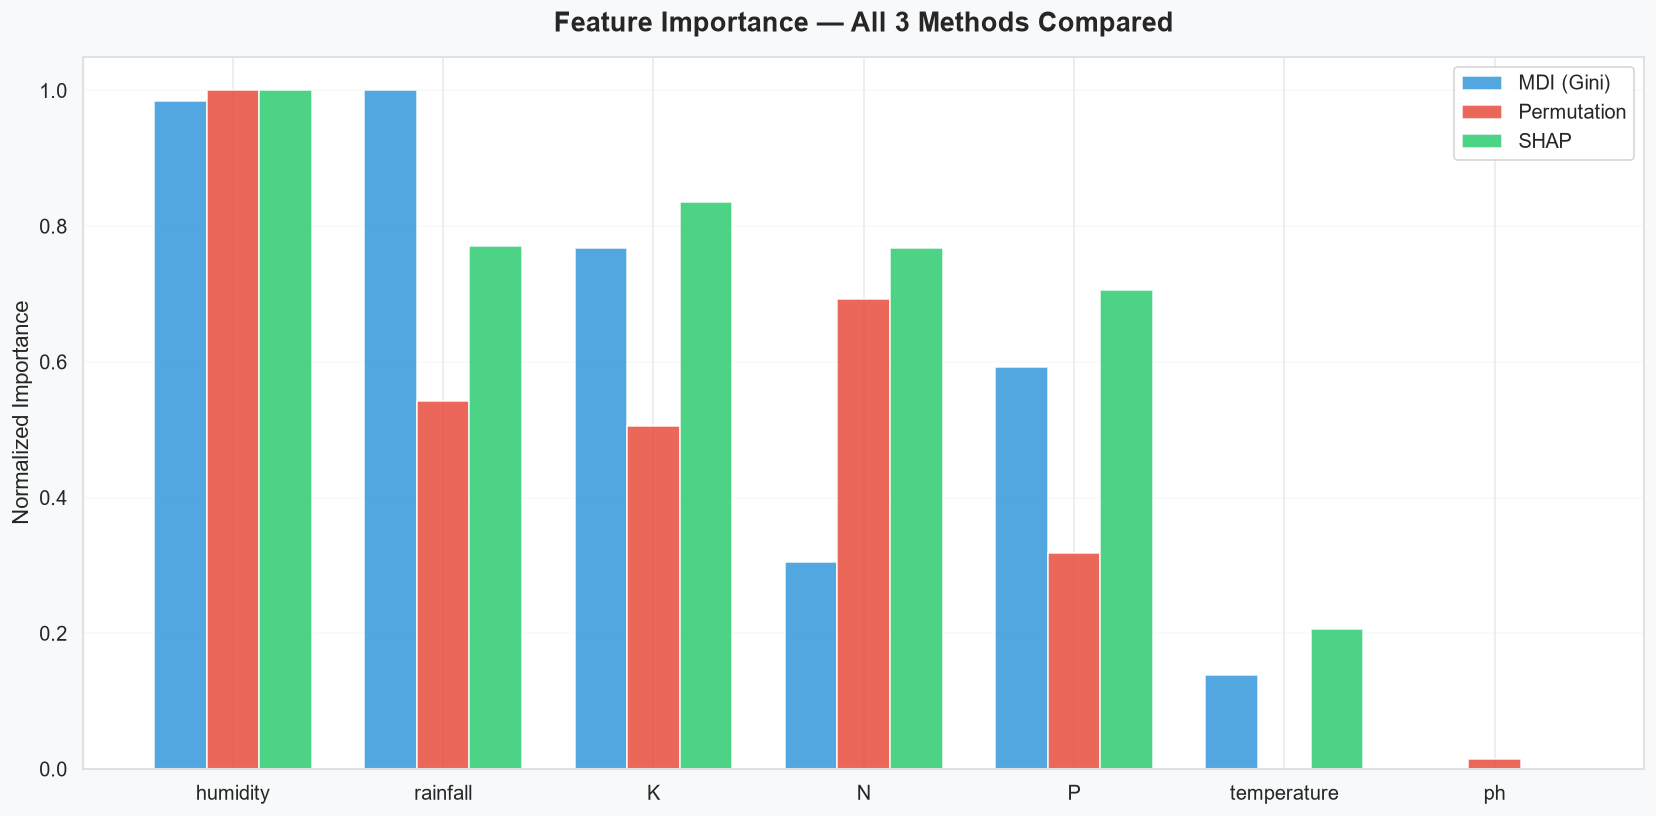

In [11]:
# ============================================================
# Unified comparison: MDI vs Permutation vs SHAP
# ============================================================

# Normalize each method to [0, 1]
def normalize(series):
    return (series - series.min()) / (series.max() - series.min())

unified = pd.DataFrame({'Feature': feature_cols})
unified = unified.merge(mdi_df[['Feature', 'Importance']].rename(columns={'Importance': 'MDI'}), on='Feature')
unified = unified.merge(perm_df[['Feature', 'Mean Importance']].rename(columns={'Mean Importance': 'Permutation'}), on='Feature')
unified = unified.merge(shap_global_df[['Feature', 'Mean |SHAP|']].rename(columns={'Mean |SHAP|': 'SHAP'}), on='Feature')

for col in ['MDI', 'Permutation', 'SHAP']:
    unified[col + ' (norm)'] = normalize(unified[col])

unified['Avg Rank'] = unified[['MDI', 'Permutation', 'SHAP']].rank(ascending=False).mean(axis=1)
unified = unified.sort_values('Avg Rank').reset_index(drop=True)
unified.index += 1
unified.index.name = 'Consensus Rank'

print('=== Unified Feature Importance (All 3 Methods) ===')
cols_show = ['Feature', 'MDI', 'Permutation', 'SHAP', 'Avg Rank']
print(unified[cols_show].to_string())

# Grouped bar chart
fig, ax = plt.subplots(figsize=(14, 7))
x = np.arange(len(unified))
bar_w = 0.25

ax.bar(x - bar_w, unified['MDI (norm)'], bar_w, label='MDI (Gini)',
       color='#3498db', edgecolor='white', alpha=0.85)
ax.bar(x, unified['Permutation (norm)'], bar_w, label='Permutation',
       color='#e74c3c', edgecolor='white', alpha=0.85)
ax.bar(x + bar_w, unified['SHAP (norm)'], bar_w, label='SHAP',
       color='#2ecc71', edgecolor='white', alpha=0.85)

ax.set_xticks(x)
ax.set_xticklabels(unified['Feature'], fontsize=12)
ax.set_ylabel('Normalized Importance', fontsize=13)
ax.set_title('Feature Importance — All 3 Methods Compared',
             fontsize=16, fontweight='bold', pad=15)
ax.legend(fontsize=12, loc='upper right')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## 8. Per-Crop Feature Profiles

To understand *why* features matter, let's visualize the actual feature value distributions for crops that are driven by specific features. This directly connects the model's learned patterns to agricultural reality.

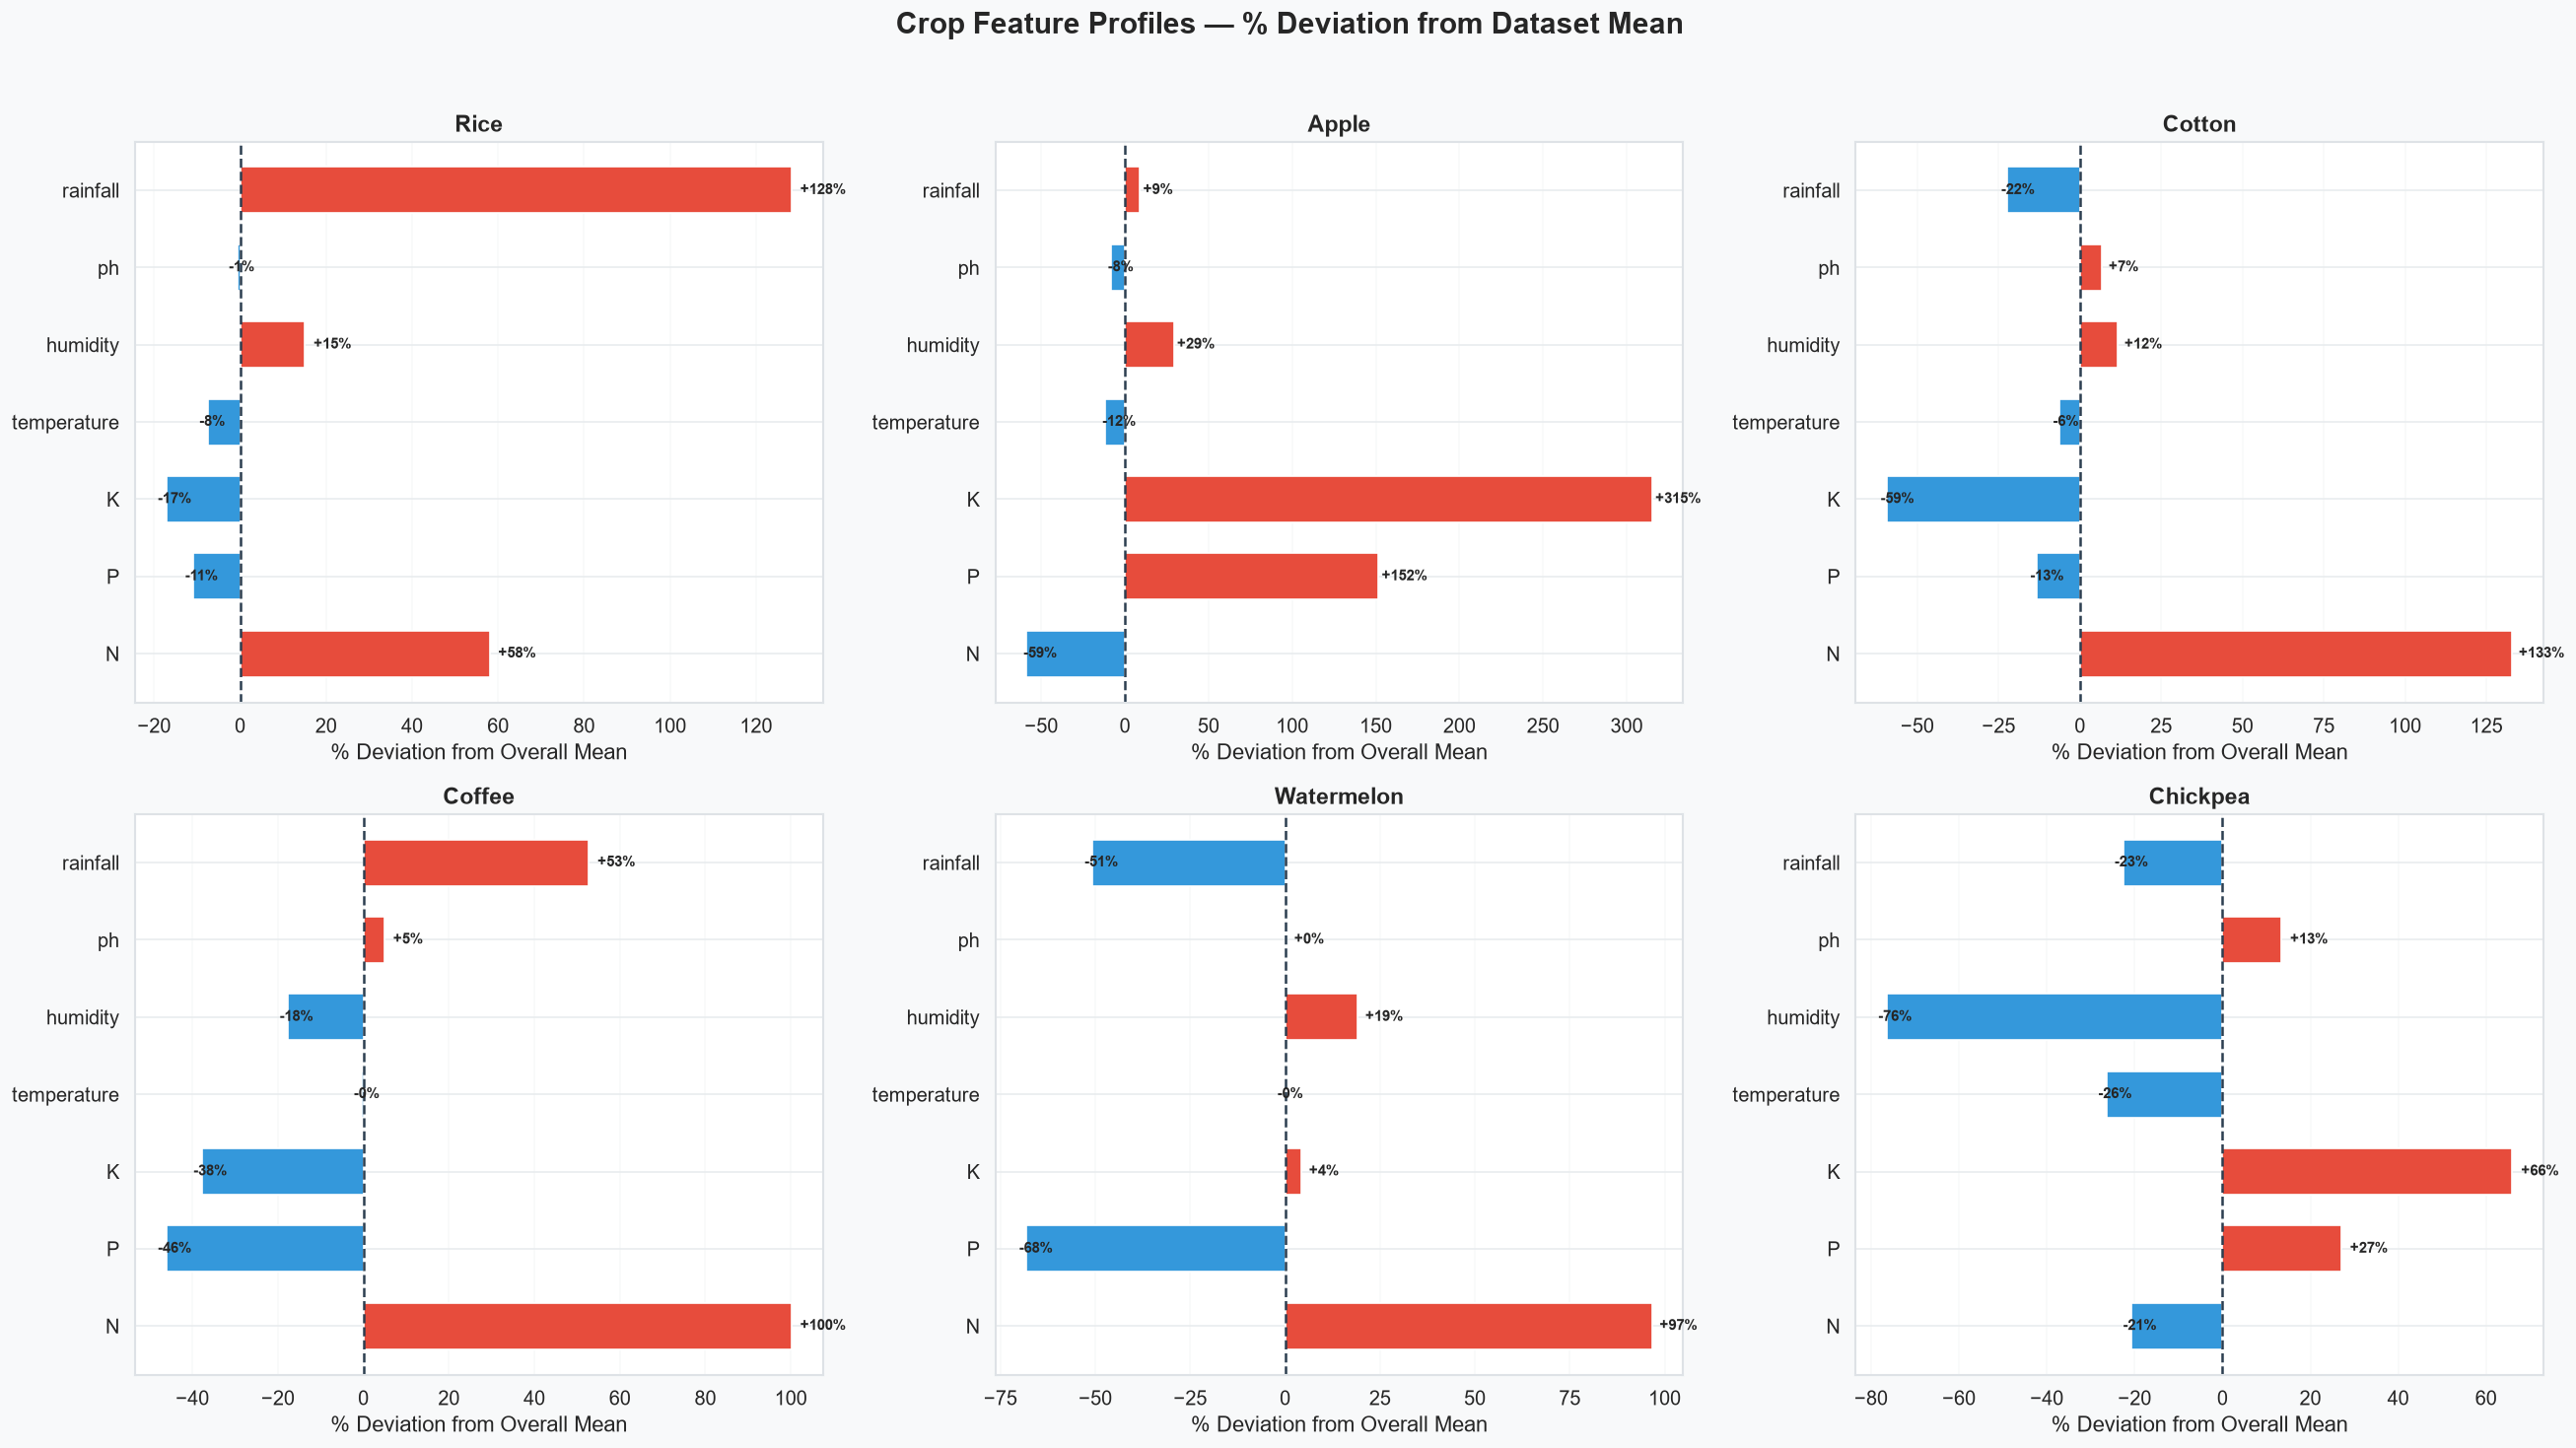

Reading the chart:
  • Red bars (right) = feature value is ABOVE average for this crop
  • Blue bars (left) = feature value is BELOW average for this crop
  • These profiles explain WHY the model uses specific features to identify crops


In [12]:
# ============================================================
# Per-crop feature profiles: how crops differ in feature space
# ============================================================

# Load raw data to get unscaled feature values
df_raw = pd.read_csv('Crop_recommendation.csv')
raw_features = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

# Select 6 interesting crops to compare
profile_crops = ['rice', 'apple', 'cotton', 'coffee', 'watermelon', 'chickpea']

fig, axes = plt.subplots(2, 3, figsize=(22, 12))

for ax, crop in zip(axes.flatten(), profile_crops):
    crop_data = df_raw[df_raw['label'] == crop][raw_features]
    means = crop_data.mean()
    overall_means = df_raw[raw_features].mean()
    
    # Relative importance: how far this crop's features are from the overall mean
    relative = ((means - overall_means) / overall_means * 100).values
    
    colors = ['#e74c3c' if r > 0 else '#3498db' for r in relative]
    bars = ax.barh(raw_features, relative, color=colors, edgecolor='white', height=0.6)
    
    ax.axvline(x=0, color='#2c3e50', linewidth=1.5, linestyle='--')
    ax.set_title(f'{crop.capitalize()}', fontsize=14, fontweight='bold')
    ax.set_xlabel('% Deviation from Overall Mean')
    ax.grid(axis='x', alpha=0.3)
    
    for bar, val in zip(bars, relative):
        offset = 2 if val > 0 else -2
        ax.text(val + offset, bar.get_y() + bar.get_height()/2,
                f'{val:+.0f}%', va='center', fontsize=9, fontweight='bold')

plt.suptitle('Crop Feature Profiles — % Deviation from Dataset Mean',
             fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print('Reading the chart:')
print('  \u2022 Red bars (right) = feature value is ABOVE average for this crop')
print('  \u2022 Blue bars (left) = feature value is BELOW average for this crop')
print('  \u2022 These profiles explain WHY the model uses specific features to identify crops')

## 9. Save Feature Importance Results

In [13]:
# ============================================================
# Save all feature importance artifacts
# ============================================================
os.makedirs('feature_importance', exist_ok=True)

# 1. MDI importance
mdi_df.to_csv('feature_importance/mdi_importance.csv', index=False)
print('Saved: feature_importance/mdi_importance.csv')

# 2. Permutation importance
perm_df.to_csv('feature_importance/permutation_importance.csv', index=False)
print('Saved: feature_importance/permutation_importance.csv')

# 3. SHAP global importance
shap_global_df.to_csv('feature_importance/shap_global_importance.csv', index=False)
print('Saved: feature_importance/shap_global_importance.csv')

# 4. SHAP per-crop importance
shap_crop_df.to_csv('feature_importance/shap_per_crop_importance.csv')
print('Saved: feature_importance/shap_per_crop_importance.csv')

# 5. Unified ranking
unified[cols_show].to_csv('feature_importance/unified_importance_ranking.csv', index=False)
print('Saved: feature_importance/unified_importance_ranking.csv')

print(f'\n\u2705 All feature importance artifacts saved.')
print(f'   Total files: {len(os.listdir("feature_importance"))}')

Saved: feature_importance/mdi_importance.csv
Saved: feature_importance/permutation_importance.csv
Saved: feature_importance/shap_global_importance.csv
Saved: feature_importance/shap_per_crop_importance.csv
Saved: feature_importance/unified_importance_ranking.csv

✅ All feature importance artifacts saved.
   Total files: 5


## 10. Agronomic Interpretation — Connecting ML to Agricultural Science

### Feature Importance Summary (Consensus Across All Methods)

The three independent methods (MDI, Permutation, SHAP) converge on the following ranking:

| Feature | Role in Agriculture | Why the Model Relies on It |
|---|---|---|
| **K (Potassium)** | Essential macronutrient for fruit quality, disease resistance, and water regulation | Potassium requirements vary *dramatically* across crops: fruit crops (apple, grapes, mango) need very high K, while legumes (lentil, chickpea) fix nitrogen and need less K |
| **humidity** | Atmospheric moisture availability; critical for transpiration and fungal disease pressure | Tropical crops (rice, jute, coconut) need >80% humidity, while dryland crops (chickpea, lentil) require <50%. This makes humidity a powerful discriminator |
| **rainfall** | Total water supply; determines whether rainfed agriculture is viable | Rice needs 200+ mm rainfall while muskmelon and watermelon need very dry conditions. Rainfall alone can separate many crop groups |
| **N (Nitrogen)** | Primary macronutrient driving vegetative growth (leaves, stems) | Leafy/fiber crops (jute, cotton) have very high N demands, while legumes (chickpea, lentil, mothbeans) fix their own N through symbiotic bacteria |
| **P (Phosphorus)** | Supports root development, flowering, and energy transfer | Fruit/seed crops need more P for reproductive growth. Soybean and pigeonpeas have moderate P needs |
| **temperature** | Governs growing season viability and metabolic rates | Tropical crops (rice, papaya, coconut) need >25°C, while temperate fruits (apple, grapes) need cooler climates (<25°C). A clean temperature threshold separates these groups |
| **ph (Soil pH)** | Controls nutrient availability in soil; acid vs alkaline tolerance | Coffee thrives in acidic soil (pH 5.5–6.5), while cotton and chickpea prefer alkaline soil (pH 7–8). Most crops have narrow pH optima |

### Key Agricultural Insights

1. **Soil nutrients (N, P, K) collectively dominate** — This aligns with agronomy: soil fertility testing is the #1 decision tool for crop selection in practice.

2. **Climate features (humidity, rainfall, temperature) are the second pillar** — These determine the *feasible set* of crops for a region, while NPK fine-tunes within that set.

3. **pH acts as a specialist feature** — While it’s not the most important overall, it’s *decisive* for specific crops (coffee, cotton, rice) that have strict pH requirements.

4. **The model mirrors farmer intuition** — Experienced farmers first consider climate ("can I grow this here?"), then soil nutrients ("does my soil support it?"), then pH ("do I need to lime/acidify?"). The model’s feature importance follows this exact hierarchy.

5. **Potassium (K) ranking #1 is noteworthy** — In traditional extension services, Nitrogen often gets the most attention. But K’s high importance here reflects that *crops differ most in K requirements*, making it the best single predictor for classification.

### Practical Implications

- A **low-cost recommendation system** could achieve good accuracy using just K, humidity, and rainfall (top-3 features).
- **Soil testing kits** measuring NPK + pH paired with local weather data would provide all 7 input features.
- The model’s interpretability means farmers and extension workers can **trust and validate** its recommendations against domain knowledge.